# Clean the Dataset

- Remove outliers based on 2std
- Remove duplicate edges


In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

In [2]:
# Config
BASE_PATH_DATASET = Path("..", "data")
MIN_SIZE_BIGGEST_COMPONENT = 15

df_nodes = pd.read_csv(Path(BASE_PATH_DATASET, "original", "nodes.csv"))
df_edges = pd.read_csv(Path(BASE_PATH_DATASET, "original", "edges.csv"))

## Nodes

Remove rows with inf, and Nan


In [3]:
n_start = len(df_nodes)
num_cols = df_nodes.select_dtypes(include=np.number).columns
report = (
    pd.DataFrame(
        {
            "nan": df_nodes.isna().sum(),
            "inf": np.isinf(df_nodes[num_cols]).sum(),  # non-numeric columns (username) get NaN here
        }
    )
    .fillna(0)
    .astype(int)
)
report["total_bad"] = report["nan"] + report["inf"]
print(report)

# Remove inf and nan from the dataset
df_nodes_clean = df_nodes.replace([np.inf, -np.inf], np.nan).dropna()
print(
    f"\nAfter inf/NaN removal: {len(df_nodes_clean)} rows "
    f"(lost {n_start - len(df_nodes_clean)}, {100 * (1 - len(df_nodes_clean) / n_start):.1f}%)"
)


                   nan  inf  total_bad
accuracy             0    0          0
acpl                 0    0          0
avg_move_time        0   22         22
draw_rate            0    0          0
frac_blunders        0    0          0
frac_inaccuracies    0    0          0
frac_mistakes        0    0          0
last_theory_ply      0    0          0
loss_rate            0    0          0
loss_streak          0    0          0
num_games            0    0          0
num_moves            0    0          0
target_rating        0    0          0
username             0    0          0
win_rate             0    0          0
win_streak           0    0          0

After inf/NaN removal: 7549 rows (lost 22, 0.3%)


Have a look at outliers, and remove rows that are more than 2 std deviations from the mean


In [4]:
feature_cols = [c for c in df_nodes_clean.select_dtypes(include=np.number).columns if c != "target_rating"]
z = (df_nodes_clean[feature_cols] - df_nodes_clean[feature_cols].mean()) / df_nodes_clean[feature_cols].std()
outlier_mask = z.abs() > 2

print("\nOutliers per feature:")
print(outlier_mask.sum().sort_values(ascending=False))

df_nodes_final = df_nodes_clean[~outlier_mask.any(axis=1)]
print(
    f"\nAfter outlier removal: {len(df_nodes_final)} rows "
    f"(lost {len(df_nodes_clean) - len(df_nodes_final)}, "
    f"{100 * (1 - len(df_nodes_final) / len(df_nodes_clean)):.1f}% of cleaned, "
    f"{100 * (1 - len(df_nodes_final) / n_start):.1f}% of original)"
)

display(df_nodes_clean["target_rating"].describe().to_frame(name="target_rating without nans"))
display(df_nodes_final["target_rating"].describe().to_frame(name="target_rating final"))

# Remove the edges to and from nodes that don't exist anymore.
# Otherwise networkx still creates these nodes
valid_users = set(df_nodes_final["username"])
n_edges_before = len(df_edges)
df_edges_clean = df_edges[df_edges["from"].isin(valid_users) & df_edges["to"].isin(valid_users)]
print(
    f"Edges: {n_edges_before} -> {len(df_edges_clean)} "
    f"(lost {n_edges_before - len(df_edges_clean)}, "
    f"{100 * (1 - len(df_edges_clean) / n_edges_before):.1f}%)"
)


Outliers per feature:
win_rate             472
loss_rate            471
frac_mistakes        379
accuracy             377
frac_inaccuracies    373
frac_blunders        364
acpl                 352
last_theory_ply      340
num_moves            319
num_games            291
draw_rate            256
avg_move_time        241
win_streak           193
loss_streak          159
dtype: int64

After outlier removal: 5172 rows (lost 2377, 31.5% of cleaned, 31.7% of original)


,target_rating without nans
count,7549.000000
mean,1531.946086
std,308.329583
min,400.000000
25%,1326.000000
50%,1539.000000
75%,1734.000000
max,2591.000000


,target_rating final
count,5172.000000
mean,1541.429234
std,260.642943
min,736.000000
25%,1360.000000
50%,1548.000000
75%,1724.000000
max,2432.000000


Edges: 21809 -> 10446 (lost 11363, 52.1%)


Finally, we remove connected components that are too small


In [5]:
G = nx.DiGraph()
G.add_nodes_from(df_nodes_final.drop_duplicates("username").set_index("username").to_dict("index").items())
G.add_weighted_edges_from(df_edges_clean[["from", "to", "points"]].itertuples(index=False, name=None))

# Sanity check: no ghosts should remain
assert all(d for _, d in G.nodes(data=True)), "ghost nodes still present"
print(G.number_of_nodes(), G.number_of_edges())

5172 7624


Nodes without attributes (ghosts): 0 of 5172
467 components, largest = 4494, nodes in largest = 86.9%


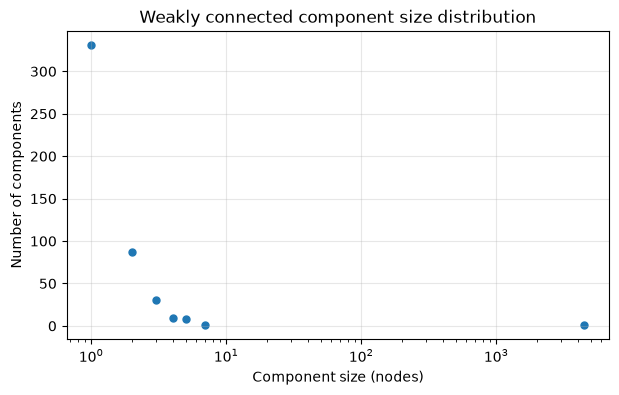

min_size=   2: keep 4841 nodes (93.6%), 136 components
min_size=   3: keep 4667 nodes (90.2%), 49 components
min_size=   5: keep 4541 nodes (87.8%), 10 components
min_size=  10: keep 4494 nodes (86.9%), 1 components
min_size=  50: keep 4494 nodes (86.9%), 1 components
min_size= 100: keep 4494 nodes (86.9%), 1 components


In [6]:
# Check for "ghost" nodes: edges pointing to users that were removed during cleaning
# have no attributes but still get created as nodes by add_weighted_edges_from.
n_ghost = sum(1 for _, d in G.nodes(data=True) if not d)
print(f"Nodes without attributes (ghosts): {n_ghost} of {G.number_of_nodes()}")

# Component sizes
components = list(nx.weakly_connected_components(G))
sizes = sorted((len(c) for c in components), reverse=True)
print(f"{len(components)} components, largest = {sizes[0]}, nodes in largest = {100 * sizes[0] / G.number_of_nodes():.1f}%")

size_counts = Counter(sizes)
xs, ys = zip(*sorted(size_counts.items()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(xs, ys, s=25)
ax.set_xscale("log")
ax.set_xlabel("Component size (nodes)")
ax.set_ylabel("Number of components")
ax.set_title("Weakly connected component size distribution")
ax.grid(alpha=0.3)
plt.show()

# Quick table of what a minimum-size cutoff would do
for min_size in [2, 3, 5, 10, 50, 100]:
    kept = sum(s for s in sizes if s >= min_size)
    print(
        f"min_size={min_size:>4}: keep {kept} nodes "
        f"({100 * kept / G.number_of_nodes():.1f}%), "
        f"{sum(1 for s in sizes if s >= min_size)} components"
    )

In [7]:
keep = set().union(*(c for c in components if len(c) >= min_size))
G_big = G.subgraph(keep).copy()

print(G_big.number_of_nodes(), G_big.number_of_edges())

# Keep your dataframe in sync with the graph
df_nodes_big = df_nodes_final[df_nodes_final["username"].isin(keep)]

4494 7372


## Edges

Drop the duplicate edges, and make sure that both the source and the target node are still in the dataset.

In [8]:
# Remove edges from or to nodes that don't exist anymore
n_start_edges = len(df_edges_clean)
valid_users = set(df_nodes_big["username"])
df_edges_clean = df_edges_clean[df_edges_clean["from"].isin(valid_users) & df_edges_clean["to"].isin(valid_users)]

# Remove duplicates
df_deduplicated_edges = df_edges_clean.drop_duplicates(["from", "to"], keep="first").reset_index(drop=True)
print(f"Edges: {n_start_edges} -> {len(df_edges_clean)} -> {len(df_deduplicated_edges)}, "
    f"(lost {n_start_edges - len(df_deduplicated_edges)}, "
    f"{100 * (1 - len(df_deduplicated_edges) / n_start_edges):.1f}%)"
)

Edges: 10446 -> 10018 -> 7372, (lost 3074, 29.4%)


## Finally

Save the data.
Note, that we have lost quite a bit of data. At this point we went from 7549 nodes to 4494. And we went from 21809 edges to 7372!

In [9]:
df_deduplicated_edges.to_csv(Path(BASE_PATH_DATASET, "cleaned", "edges.csv"), index=False)
df_nodes_big.to_csv(Path(BASE_PATH_DATASET, "cleaned", "nodes.csv"), index=False)